In [29]:
# Importing Data Set
import gc
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [30]:
# Mount Google Drive and load data
drive.mount("/content/drive")
df = pd.read_csv(
    "/content/drive/MyDrive/Reviews.csv",
    engine="python",
    on_bad_lines="skip",
)
df = df.dropna(subset=["Text", "Score"]).copy()
df["Score"] = df["Score"].astype(int)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
# Print dataset shape
print(df.shape)

(568454, 10)


In [32]:
# Display a sample review
print(f"Score: {df['Score'].iloc[0]}")
print(df["Text"].iloc[0])

Score: 5
I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.


In [33]:
# Check label distribution
y_all = df["Score"].values - 1
pd.Series(df["Score"]).value_counts().sort_index()

,count
Score,
1,52268
2,29769
3,42640
4,80655
5,363122


In [34]:
# Check data types
print(type(df["Text"]))
print(type(df["Text"].iloc[0]))

<class 'pandas.core.series.Series'>
<class 'str'>


In [35]:
# Clean text and split into train and test sets
def clean_text(text):
  text = str(text).lower()
  text = re.sub(r"<.*?>", " ", text)
  text = re.sub(r"http\S+|www\S+", " ", text)
  text = text.translate(str.maketrans("", "", string.punctuation))
  text = re.sub(r"\s+", " ", text).strip()
  return text


cleaned_text = df["Text"].apply(clean_text)
del df
gc.collect()



30

In [36]:
x_train_text, x_test_text, y_train, y_test = train_test_split(
    cleaned_text, y_all, test_size=0.2, random_state=42, stratify=y_all
)
del cleaned_text, y_all
gc.collect()

print(x_train_text.shape)
print(x_test_text.shape)

(454763,)
(113691,)


In [37]:
# Apply TF-IDF normalization / feature scaling
vectorizer = TfidfVectorizer(max_features=1500, ngram_range=(1, 1))
x_train = vectorizer.fit_transform(x_train_text).astype("float32").toarray()
x_test = vectorizer.transform(x_test_text).astype("float32").toarray()
del x_train_text, x_test_text
gc.collect()

# Print processed shapes
print(x_train.shape)
print(x_test.shape)

(454763, 1500)
(113691, 1500)


In [38]:
# Build Sequential Model
from keras.models import Sequential
from keras.layers import Dense

# Define Sequential Model
model = Sequential()

# Add input layer
model.add(Dense(units=128, activation="relu", input_dim=x_train.shape[1]))

# Add hidden layer
model.add(Dense(units=64, activation="relu"))

# Add second hidden layer
model.add(Dense(units=32, activation="relu"))

# Add output layer
model.add(Dense(units=5, activation="softmax"))

# Model summary
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │       192,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 202,629 (791.52 KB)

 Trainable params: 202,629 (791.52 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [40]:
# Fit the model
history = model.fit(
    x_train, y_train, epochs=15, batch_size=512, validation_split=0.2
)

Epoch 1/15
711/711 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - accuracy: 0.7040 - loss: 0.8074 - val_accuracy: 0.7253 - val_loss: 0.7339
Epoch 2/15
711/711 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.7410 - loss: 0.6986 - val_accuracy: 0.7415 - val_loss: 0.6965
Epoch 3/15
711/711 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.7688 - loss: 0.6299 - val_accuracy: 0.7551 - val_loss: 0.6703
Epoch 4/15
711/711 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.7932 - loss: 0.5695 - val_accuracy: 0.7645 - val_loss: 0.6649
Epoch 5/15
711/711 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.8147 - loss: 0.5183 - val_accuracy: 0.7699 - val_loss: 0.6701
Epoch 6/15
711/711 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.8335 - loss: 0.4729 - val_accuracy: 0.7736 - val_loss: 0.6785
Epoch 7/15
711/711 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.8494 - loss: 0.4321 - val_accuracy: 0.7753 - val_loss: 0.6987
Epoch 8/15
711/711 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.8628 - loss: 0.3965 - 

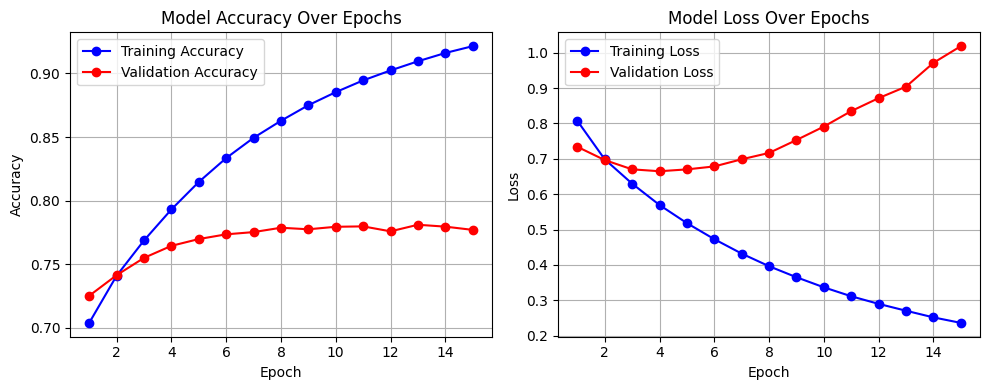

In [41]:
# Extract metrics from history
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(acc) + 1)

# Plot Accuracy and Loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, "bo-", label="Training Accuracy")
plt.plot(epochs, val_acc, "ro-", label="Validation Accuracy")
plt.title("Model Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, "bo-", label="Training Loss")
plt.plot(epochs, val_loss, "ro-", label="Validation Loss")
plt.title("Model Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [42]:
# Evaluate the model on test data
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_acc = model.evaluate(x_test, y_test, batch_size=512, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 1.0205
Test Accuracy: 0.7772


In [43]:
# Predict class probabilities and convert to class indices (0..4)
y_pred_probs = model.predict(x_test, batch_size=1024, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

In [44]:
# Print classification report
target_names = ["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"]
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=target_names))


Classification Report:

              precision    recall  f1-score   support

      1 Star       0.69      0.71      0.70     10454
     2 Stars       0.51      0.46      0.48      5954
     3 Stars       0.54      0.49      0.51      8528
     4 Stars       0.58      0.50      0.53     16131
     5 Stars       0.87      0.91      0.89     72624

    accuracy                           0.78    113691
   macro avg       0.64      0.61      0.62    113691
weighted avg       0.77      0.78      0.77    113691



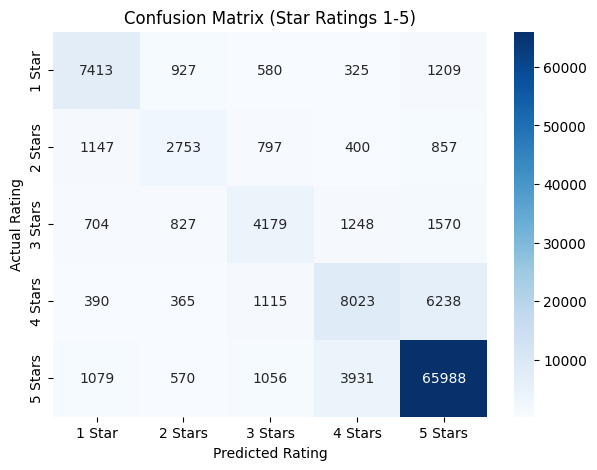

In [45]:
# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
)
plt.title("Confusion Matrix (Star Ratings 1-5)")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.show()

In [46]:
# Map star rating (1-5) to sentiment
def get_sentiment(rating):
  if rating >= 4:
    return "Positive"
  elif rating <= 2:
    return "Negative"
  else:
    return "Neutral"


In [47]:
# Show sample predictions
sample_reviews = [
    "This product is amazing and tastes great. I will buy it again!",
    "Terrible quality and bad taste. Complete waste of money.",
    "It is okay, nothing special, just average for the price.",
]

sample_cleaned = [clean_text(r) for r in sample_reviews]
sample_tfidf = vectorizer.transform(sample_cleaned).astype("float32").toarray()
sample_probs = model.predict(sample_tfidf, verbose=0)
sample_preds = np.argmax(sample_probs, axis=1) + 1

print("\nSample Predictions:")
for rev, rating, probs in zip(sample_reviews, sample_preds, sample_probs):
  print(f"\nReview: {rev}")
  print(
      f"Predicted Rating: {rating} | Sentiment: {get_sentiment(rating)} |"
      f" Confidence: {np.max(probs):.2f}"
  )


Sample Predictions:

Review: This product is amazing and tastes great. I will buy it again!
Predicted Rating: 5 | Sentiment: Positive | Confidence: 0.98

Review: Terrible quality and bad taste. Complete waste of money.
Predicted Rating: 1 | Sentiment: Negative | Confidence: 1.00

Review: It is okay, nothing special, just average for the price.
Predicted Rating: 3 | Sentiment: Neutral | Confidence: 1.00


In [48]:
from google.colab import files
import joblib

model.save("final_ann_model.keras")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

files.download("final_ann_model.keras")
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>